In [26]:

from transformers import GPT2LMHeadModel

In [27]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") #124M for Billiion model use gpt2-XL
sd_hf = model_hf.state_dict()

for k,v  in sd_hf.items():
    print(k, v.shape)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [28]:
sd_hf["transformer.wpe.weight"].view(-1)[:20]

tensor([-0.0188, -0.1974,  0.0040,  0.0113,  0.0638, -0.1050,  0.0369, -0.1680,
        -0.0491, -0.0565, -0.0025,  0.0135, -0.0042,  0.0151,  0.0166, -0.1381,
        -0.0063, -0.0461,  0.0267, -0.2042])

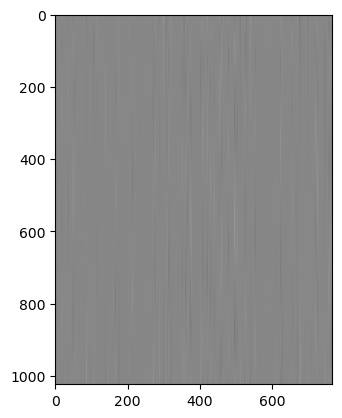

In [29]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.imshow(sd_hf["transformer.wpe.weight"], cmap="gray")
plt.show()

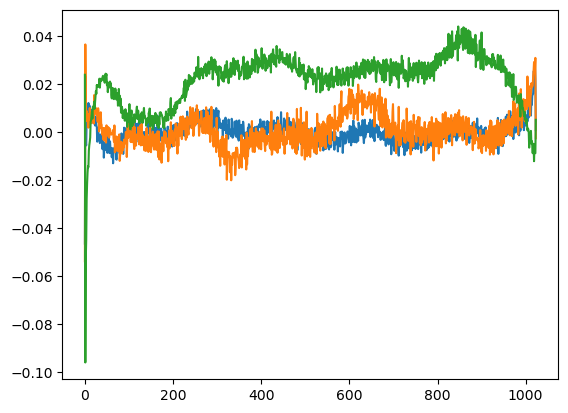

In [30]:
plt.plot(sd_hf["transformer.wpe.weight"][:, 150])
plt.plot(sd_hf["transformer.wpe.weight"][:, 200])
plt.plot(sd_hf["transformer.wpe.weight"][:, 250])
plt.show()

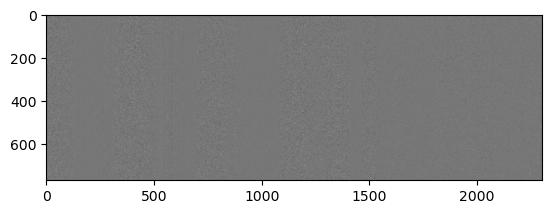

In [31]:
plt.imshow(sd_hf["transformer.h.1.attn.c_attn.weight"], cmap="gray")
plt.show()

In [33]:
from transformers import pipeline, set_seed
generator = pipeline('text-generation', model ='gpt2')
set_seed(42)
generator("Hello, I'm a language model,", max_length=30, num_return_sequences=5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[{'generated_text': "Hello, I'm a language model, but what I'm really trying to do is make everything a language. And this is where I'm really happy"},
 {'generated_text': "Hello, I'm a language model, not a syntax model. I never got the chance to learn this idea. I've never been taught it in"},
 {'generated_text': "Hello, I'm a language model, and I've been working on this for a while. I am going to show you how to create a simple"},
 {'generated_text': 'Hello, I\'m a language model, not a system."\n\n"But, my code is simple."\n\n"Yes, but you\'re'},
 {'generated_text': 'Hello, I\'m a language model, I\'m not a language model. I\'m a language model."\n\n"What? What is a language'}]